# 05 Ablation and efficiency

Paired differences (oversampling minus none) with 95% intervals, and the efficiency benchmark.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 4)
RESULTS, CHECKPOINTS = ROOT / "results", ROOT / "checkpoints"

def require(*paths, hint):
    missing = [str(p) for p in paths if not Path(p).exists()]
    if missing:
        print("MISSING:", *missing, sep="\n  ")
        print("To create:", hint)
    return not missing

def runs():
    return sorted(p for p in CHECKPOINTS.iterdir() if (p / "run.json").is_file()) if CHECKPOINTS.is_dir() else []


In [2]:
AB = RESULTS / "ablation_minority.csv"
if require(AB, hint="python -m xaidr.cli ablation --run <oversample run> --against <none run>"):
    ab = pd.read_csv(AB)
    print("oversample run:", ab["run_oversample"].iloc[0]); print("none run:      ", ab["run_none"].iloc[0])
    print("interval:", ab["interval"].iloc[0])
    display(ab[["metric", "none", "oversample", "diff_oversample_minus_none", "ci_lo", "ci_hi", "ci_excludes_zero", "n", "note"]])

oversample run: 20261012-112520_convnext_tiny_oversample_seed42
none run:       20261012-102317_convnext_tiny_none_seed42
interval: paired bootstrap over test images, one training run per arm


,metric,none,oversample,diff_oversample_minus_none,ci_lo,ci_hi,ci_excludes_zero,n,note
0,minority_sensitivity_grades_3_4,0.5204,0.5718,0.0514,-0.0602,0.1580,False,526,NaN
1,sensitivity_grade_3,0.7407,0.5185,-0.2222,-0.3704,-0.0741,True,526,NaN
2,sensitivity_grade_4,0.3000,0.6250,0.3250,0.1750,0.4750,True,526,NaN
3,grading_macro_sensitivity,0.6688,0.6920,0.0232,-0.0273,0.0713,False,526,NaN
4,grading_accuracy,0.8118,0.8346,0.0228,-0.0038,0.0494,False,526,NaN
5,grading_qwk,0.9033,0.9027,-0.0006,-0.0217,0.0215,False,526,NaN
6,detection_auc,0.9990,0.9984,-0.0006,-0.0022,0.0004,False,526,NaN
7,detection_sensitivity,0.9766,0.9883,0.0117,-0.0039,0.0312,False,526,NaN
8,detection_specificity,0.9963,0.9889,-0.0074,-0.0185,0.0000,False,526,NaN
9,mean_idrid_iou_k10,NaN,NaN,NaN,NaN,NaN,False,0,not computed: needs IDRiD lesion masks and the...


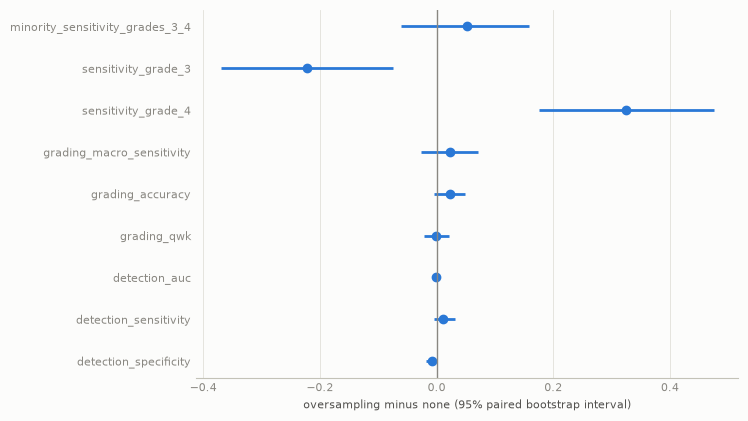

In [3]:
if AB.exists():
    import matplotlib.pyplot as plt
    done = ab.dropna(subset=["diff_oversample_minus_none"]).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.42 * len(done) + 1), facecolor="#fcfcfb")
    y = np.arange(len(done))
    ax.hlines(y, done["ci_lo"], done["ci_hi"], color="#2a78d6", linewidth=2)
    ax.plot(done["diff_oversample_minus_none"], y, "o", color="#2a78d6", markersize=6)
    ax.axvline(0, color="#898781", linewidth=1)
    ax.set_yticks(y, done["metric"], fontsize=8, color="#52514e"); ax.tick_params(length=0, labelsize=8, colors="#898781")
    ax.set_xlabel("oversampling minus none (95% paired bootstrap interval)", fontsize=8, color="#52514e")
    ax.set_facecolor("#fcfcfb"); ax.grid(axis="x", color="#e1e0d9", linewidth=0.6); ax.set_axisbelow(True)
    for side in ("top", "right", "left"): ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    fig.savefig(RESULTS / "figures" / "ablation_differences.png", dpi=220, facecolor="#fcfcfb", bbox_inches="tight")
    plt.show()

In [4]:
EF = RESULTS / "efficiency.csv"
if require(EF, hint="python -m xaidr.cli efficiency --run <run id>"):
    ef = pd.read_csv(EF)
    display(ef[["model", "device", "precision", "input_px", "params_total", "weights_mb", "checkpoint_mb",
                "latency_median_ms", "latency_iqr_ms", "peak_gpu_memory_mb", "n_timed"]])

,model,device,precision,input_px,params_total,weights_mb,checkpoint_mb,latency_median_ms,latency_iqr_ms,peak_gpu_memory_mb,n_timed
0,"Fallback baseline, NOT the specified model (th...","Intel64 Family 6 Model 140 Stepping 1, Genuine...",fp32,256,28215398,112.8616,338.776,97.6091,15.278,NaN,200
